# Predicting Weber's length from ant thoraces using CNNs

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
INNER_VAL_FRACTION = 0.15
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'notebooks/preprocessing_wl.ipynb').exists())
DATA_DIR = ROOT / 'data/processed/wl'
OUTPUT_DIR = ROOT / 'results/cnn_wl'
CHECKPOINT_DIR = OUTPUT_DIR / 'clean_checkpoints'
ANALYSIS_DIR = OUTPUT_DIR / 'analysis_scale_filtered'
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
feature_sets = json.loads((DATA_DIR / 'feature_sets.json').read_text(encoding='utf-8'))
TARGET = feature_sets['target']
LF_FEATURES = feature_sets['LF']
SIZE_FEATURES = ['major_axis_mm', 'minor_axis_mm']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RESNET_WEIGHTS = ResNet18_Weights.DEFAULT
preprocessing = RESNET_WEIGHTS.transforms()
photo_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(preprocessing.mean, preprocessing.std)])

MODEL = "all"   # For example: "mask_lf"
N_FOLDS = 5     # Use 1 for a single existing fold

## 1. Scale quality and specimen selection
Physical dimensions depend directly on the scale bar. For specimen casent0005709, the automatic reading of 200 mm produces a major axis of 231.6 mm. The manually annotated scale gives about 2.33 mm for the same pixels. The table below shows both calculations.

We exclude specimens when the automatic conversion differs from a valid manual conversion by more than 10%, or the extraction comment reports an assumed value, a weak reading or a request for review. Missing manual annotations alone do not exclude a specimen. The filter uses scale records independently of the target WL.

In [2]:
raw = pd.read_csv(DATA_DIR / "dataset_preprocessing.csv")
partitions = pd.read_csv(DATA_DIR / "partitions.csv")
data = partitions.merge(raw.drop(columns=["split", "validation_fold"], errors="ignore"),
                        on="specimen_id", validate="one_to_one")
assert len(data) == len(partitions)
case = data.loc[data.specimen_id.eq("casent0005709"),
                ["specimen_id", "major_axis_px", "scale_number", "major_axis_mm", "mm_per_px_manual"]].copy()
case["axis_from_manual_scale_mm"] = case.major_axis_px * case.mm_per_px_manual
display(case.round(4))
relative_error = (data.mm_per_px / data.mm_per_px_manual - 1).abs()
disagreement = relative_error.gt(0.10)
uncertain = data.scale_comments.str.contains(r"assum|please check|\bweak\b", case=False, na=False)
exclude = disagreement | uncertain
display(pd.Series({"Initially eligible": len(data), "Manual comparisons": relative_error.notna().sum(),
                   "Scale disagreements": disagreement.sum(), "Excluded (union)": exclude.sum(),
                   "Retained": (~exclude).sum()}, name="Specimens").to_frame())
cv_data = data.loc[~exclude & data.split.eq("development")].copy()
display(cv_data.groupby("validation_fold").size().rename("Development specimens").to_frame())

,specimen_id,major_axis_px,scale_number,major_axis_mm,mm_per_px_manual,axis_from_manual_scale_mm
226,casent0005709,327.7379,2.0,2.3161,0.0071,2.3288


,Specimens
Initially eligible,3506
Manual comparisons,486
Scale disagreements,13
Excluded (union),42
Retained,3464


,Development specimens
validation_fold,
1.0,554
2.0,549
3.0,556
4.0,554
5.0,556


## 2. Six model configurations

| Model key | Image input | Numeric input |
|---|---|---|
| dimensions_only | None | Major and minor axes |
| lf_only | None | Length and shape features (LF) |
| mask_sizes | Binary thorax mask | Major and minor axes |
| mask_lf | Binary thorax mask | LF |
| photo_sizes | RGB thorax photograph | Major and minor axes |
| photo_lf | RGB thorax photograph | LF |

The two axes are measured in millimetres before image resizing. LF combines five lengths with square-root area, axis ratio, solidity, bounding-box occupancy and perimeter. All image inputs are 224 x 224 pixels.

In [3]:
EXPERIMENTS = {
 'dimensions_only': ('numeric', SIZE_FEATURES), 'lf_only': ('numeric', LF_FEATURES),
 'mask_sizes': ('mask', SIZE_FEATURES), 'mask_lf': ('mask', LF_FEATURES),
 'photo_sizes': ('photo', SIZE_FEATURES), 'photo_lf': ('photo', LF_FEATURES),
}
print("LF columns:", LF_FEATURES)

LF columns: ['feret_max_mm', 'major_axis_mm', 'thorax_width_mm', 'projected_length_mm', 'minor_axis_mm', 'sqrt_area_mm', 'minor_major_ratio', 'solidity', 'extent', 'perimeter_mm']


## 3. Shared implementation
The numeric baseline uses a multilayer perceptron. The mask CNN uses three convolutional blocks and global average pooling. The photo model combines the ResNet18 representation with a numeric branch. Its pretrained backbone starts frozen; fine-tuning updates the last block while keeping batch normalization statistics fixed.

In [4]:
class FeaturesOnly(nn.Module):
    def __init__(self, num_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(num_features, 16),
            nn.ReLU(),
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, images, features):
        return self.network(features).squeeze(-1)

class MaskCNN(nn.Module):
    def __init__(self, num_features=2):
        super().__init__()

        self.mask_encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )

        self.feature_encoder = nn.Sequential(
            nn.Linear(num_features, 16),
            nn.ReLU(),
        )

        self.regressor = nn.Sequential(
            nn.Linear(64 + 16, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, masks, features):
        visual = self.mask_encoder(masks)
        numerical = self.feature_encoder(features)

        combined = torch.cat([visual, numerical], dim=1)
        return self.regressor(combined).squeeze(-1)

class PhotoResNet(nn.Module):
    def __init__(self, num_features=2):
        super().__init__()

        self.backbone = resnet18(weights=RESNET_WEIGHTS)

        self.backbone.fc = nn.Identity()

        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

        self.feature_encoder = nn.Sequential(
            nn.Linear(num_features, 16),
            nn.ReLU(),
        )

        self.regressor = nn.Sequential(
            nn.Linear(512 + 16, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def train(self, mode=True):
        super().train(mode)

        self.backbone.eval()
        return self

    def forward(self, photos, features):
        visual = self.backbone(photos)
        numerical = self.feature_encoder(features)

        combined = torch.cat([visual, numerical], dim=1)
        return self.regressor(combined).squeeze(-1)

In [5]:
class SpecimenDataset(Dataset):
    """Read the selected image modality and standardize the numeric predictors."""
    def __init__(self, frame, kind, columns, scaler):
        self.frame = frame.reset_index(drop=True)
        self.kind = kind
        self.features = torch.tensor(scaler.transform(frame[columns]), dtype=torch.float32)
        self.targets = torch.tensor(frame[TARGET].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        image = torch.tensor(0.0)
        if self.kind != "numeric":
            path = self.frame.at[index, f"thorax_{self.kind}_path"]
            with Image.open(ROOT / path) as source:
                if self.kind == "photo":
                    image = photo_transform(source.convert("RGB"))
                else:
                    image = transforms.ToTensor()(source.convert("L"))
        return image, self.features[index], self.targets[index]

In [6]:
criterion = nn.L1Loss()

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    absolute_error = 0.0
    squared_error = 0.0
    count = 0

    with torch.set_grad_enabled(training):
        for masks, features, targets in loader:
            masks = masks.to(DEVICE, non_blocking=True)
            features = features.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            predictions = model(masks, features)
            loss = criterion(predictions, targets)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss")

            if training:
                loss.backward()
                optimizer.step()

            errors = predictions.detach() - targets
            absolute_error += errors.abs().sum().item()
            squared_error += errors.square().sum().item()
            count += targets.numel()

    return {
        "mae": absolute_error / count,
        "rmse": np.sqrt(squared_error / count),
    }

def fit_phase(
    candidate, fit_loader, inner_loader, optimizer,
    epochs=30, patience=10, keep_initial=False,
):
    initial_metrics = run_epoch(candidate, inner_loader)
    best_mae = initial_metrics["mae"] if keep_initial else float("inf")
    best_epoch = 0
    best_state = {
        name: value.detach().cpu().clone()
        for name, value in candidate.state_dict().items()
    }

    rows = []
    stale_epochs = 0

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(candidate, fit_loader, optimizer)
        inner_metrics = run_epoch(candidate, inner_loader)

        rows.append({
            "epoch": epoch,
            "train_mae": train_metrics["mae"],
            "inner_val_mae": inner_metrics["mae"],
            "inner_val_rmse": inner_metrics["rmse"],
        })

        if inner_metrics["mae"] < best_mae:
            best_mae = inner_metrics["mae"]
            best_epoch = epoch
            best_state = {
                name: value.detach().cpu().clone()
                for name, value in candidate.state_dict().items()
            }
            stale_epochs = 0
        else:
            stale_epochs += 1

        if stale_epochs >= patience:
            break

    candidate.load_state_dict(best_state)

    return {
        "history": pd.DataFrame(rows),
        "best_epoch": best_epoch,
        "best_inner_mae": best_mae,
    }

## 4. Cross-validation
Each outer fold provides a common evaluation set. Within the remaining four folds, 15% of specimens select the checkpoint by MAE; only the fitting subset determines the scaler. Adam trains for up to 30 epochs per phase with patience 10. The outer fold is scored after checkpoint selection.

By default, the function restores existing weights and verifies their split and scaling. Missing checkpoints are trained. Use `retrain=True` to train fresh models in a separate output directory. The fold count selects the first folds of the shared partition.

In [7]:
def prepare_fold(fold, seed=SEED):
    evaluation_df = cv_data.loc[
        cv_data["validation_fold"] == fold
    ].copy()

    training_pool = cv_data.loc[
        cv_data["validation_fold"] != fold
    ].copy()

    training_pool = training_pool.sort_values("specimen_id")

    fit_df, inner_val_df = train_test_split(
        training_pool,
        test_size=INNER_VAL_FRACTION,
        random_state=seed,
        shuffle=True,
    )

    fit_df = fit_df.reset_index(drop=True)
    inner_val_df = inner_val_df.reset_index(drop=True)
    evaluation_df = evaluation_df.reset_index(drop=True)

    fit_ids = set(fit_df["specimen_id"])
    inner_ids = set(inner_val_df["specimen_id"])
    evaluation_ids = set(evaluation_df["specimen_id"])

    assert fit_ids.isdisjoint(inner_ids)
    assert fit_ids.isdisjoint(evaluation_ids)
    assert inner_ids.isdisjoint(evaluation_ids)

    assert (
        fit_ids | inner_ids | evaluation_ids
        == set(cv_data["specimen_id"])
    )

    fold_size_scaler = StandardScaler().fit(
        fit_df[SIZE_FEATURES]
    )
    fold_lf_scaler = StandardScaler().fit(
        fit_df[LF_FEATURES]
    )

    return {
        "fit": fit_df,
        "inner_val": inner_val_df,
        "evaluation": evaluation_df,
        "size_scaler": fold_size_scaler,
        "lf_scaler": fold_lf_scaler,
    }

def collect_predictions(candidate, loader):
    candidate.eval()
    predictions = []

    with torch.no_grad():
        for images, features, _ in loader:
            output = candidate(
                images.to(DEVICE),
                features.to(DEVICE),
            )
            predictions.append(output.cpu().numpy())

    return np.concatenate(predictions)

In [8]:
def fit_model(model, kind, loaders):
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=1e-3)
    first = fit_phase(model, loaders["fit"], loaders["inner_val"], optimizer)
    history = first["history"].assign(phase="initial", selected_epoch=first["best_epoch"])
    if kind == "photo":
        model.backbone.layer4.requires_grad_(True)
        optimizer = torch.optim.Adam([
            {"params": model.backbone.layer4.parameters(), "lr": 1e-5},
            {"params": model.feature_encoder.parameters(), "lr": 1e-4},
            {"params": model.regressor.parameters(), "lr": 1e-4},
        ])
        last = fit_phase(model, loaders["fit"], loaders["inner_val"], optimizer, keep_initial=True)
        history = pd.concat([history, last["history"].assign(phase="fine_tuning", selected_epoch=last["best_epoch"])])
    return history


def run_experiments(model="all", n_folds=5, retrain=False):
    """Return out-of-fold predictions for the selected models and existing folds."""
    if model != "all" and model not in EXPERIMENTS:
        raise ValueError(f"Unknown model: {model}")
    if type(n_folds) is not int or not 1 <= n_folds <= 5:
        raise ValueError("n_folds must be an integer from 1 to 5")
    predictions = []
    fresh_dir = CHECKPOINT_DIR
    for fold in range(1, n_folds + 1):
        groups = prepare_fold(fold, seed=SEED)
        ids = {s: groups[s].specimen_id.tolist() for s in ("fit", "inner_val", "evaluation")}
        for name in (EXPERIMENTS if model == "all" else [model]):
            kind, columns = EXPERIMENTS[name]
            scaler = groups["lf_scaler" if columns == LF_FEATURES else "size_scaler"]
            torch.manual_seed(SEED)
            cls = {"numeric": FeaturesOnly, "mask": MaskCNN, "photo": PhotoResNet}[kind]
            candidate = cls(len(columns)).to(DEVICE)
            loaders = {
                s: DataLoader(SpecimenDataset(groups[s], kind, columns, scaler),
                              batch_size=32, shuffle=(s == "fit"),
                              generator=torch.Generator().manual_seed(SEED))
                for s in ids
            }
            filename = f"{name}_fold{fold}.pt"
            checkpoint_path = CHECKPOINT_DIR / filename
            if checkpoint_path.exists() and not retrain:
                checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
                split_ids = checkpoint.get("split_ids") or {s: checkpoint[s + "_ids"] for s in ids}
                assert split_ids == ids and checkpoint["feature_columns"] == columns
                np.testing.assert_allclose(checkpoint["scaler_mean"], scaler.mean_)
                np.testing.assert_allclose(checkpoint["scaler_scale"], scaler.scale_)
                candidate.load_state_dict(checkpoint["model_state_dict"])
            else:
                fresh_dir.mkdir(exist_ok=True)
                history = fit_model(candidate, kind, loaders)
                history.to_csv(fresh_dir / f"{name}_fold{fold}_history.csv", index=False)
                torch.save({"model_state_dict": candidate.state_dict(), "split_ids": ids,
                            "feature_columns": columns, "scaler_mean": scaler.mean_.tolist(),
                            "scaler_scale": scaler.scale_.tolist()}, fresh_dir / filename)
            table = groups["evaluation"][["specimen_id", TARGET]].copy()
            table["prediction_mm"] = collect_predictions(candidate, loaders["evaluation"])
            predictions.append(table.assign(model=name, fold=fold))
    result = pd.concat(predictions, ignore_index=True)
    assert not result.duplicated(["model", "specimen_id"]).any()
    return result

In [9]:
predictions = run_experiments(model=MODEL, n_folds=N_FOLDS)
print(f"{len(predictions):,} evaluation predictions")

16,614 evaluation predictions


## 5. Results

Fold averages weight each fold equally. Pooled metrics weight each specimen equally. RMSE penalizes a few large errors more heavily than MAE.

MAE                                    RMSE          \
fold                  1       2       3       4       5       1       2   
model                                                                     
dimensions_only  0.1387  0.1001  0.0950  0.1444  0.0978  0.6737  0.5140   
lf_only          0.1396  0.1005  0.0916  0.1421  0.0938  0.7112  0.6263   
mask_lf          0.1243  0.0878  0.0736  0.1087  0.0914  0.4663  0.3678   
mask_sizes       0.1238  0.0790  0.0765  0.1133  0.0960  0.4637  0.1732   
photo_lf         0.1308  0.1108  0.1106  0.1401  0.0994  0.4094  0.5148   
photo_sizes      0.1560  0.1213  0.1207  0.1508  0.1188  0.6241  0.5205   

                                         
fold                  3       4       5  
model                                    
dimensions_only  0.3948  0.7362  0.3910  
lf_only          0.4082  0.8030  0.4256  
mask_lf          0.2782  0.3582  0.3202  
mask_sizes       0.2736  0.3658  0.3232  
photo_lf         0.4000  0.6099  0.2459  
photo_sizes      0.3601  0.6459  0.3252

,mean_fold_MAE,mean_fold_RMSE,pooled_MAE,pooled_RMSE
model,,,,
mask_lf,0.0972,0.3582,0.0972,0.3635
mask_sizes,0.0977,0.3199,0.0977,0.3343
lf_only,0.1135,0.5948,0.1135,0.6146
dimensions_only,0.1152,0.5419,0.1152,0.5600
photo_lf,0.1183,0.4360,0.1183,0.4525
photo_sizes,0.1335,0.4951,0.1335,0.5122


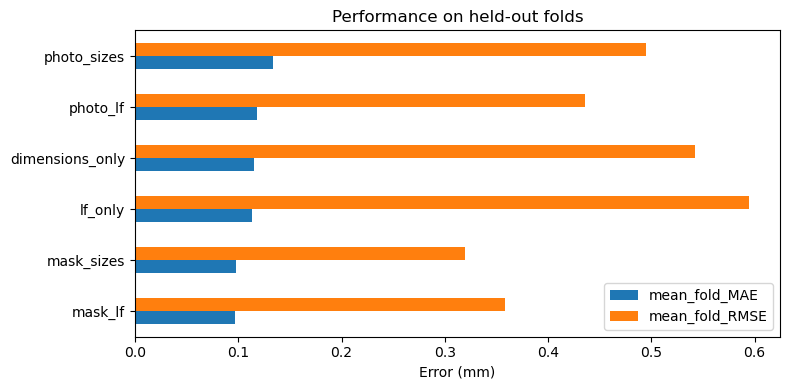

In [10]:
errors = predictions.assign(error=predictions.prediction_mm - predictions[TARGET])
def score(frame, keys):
    return (frame.assign(abs_error=frame.error.abs(), squared_error=frame.error ** 2)
            .groupby(keys).agg(MAE=("abs_error", "mean"), RMSE=("squared_error", "mean"))
            .assign(RMSE=lambda x: np.sqrt(x.RMSE)))

fold_scores = score(errors, ["model", "fold"])
summary = fold_scores.groupby(level="model").mean().add_prefix("mean_fold_")
summary = summary.join(score(errors, "model").add_prefix("pooled_")).sort_values("mean_fold_MAE")
display(fold_scores.unstack().round(4))
display(summary.round(4))
ax = summary[["mean_fold_MAE", "mean_fold_RMSE"]].plot.barh(figsize=(8, 4))
ax.set(xlabel="Error (mm)", ylabel="", title="Performance on held-out folds")
plt.tight_layout()
plt.show()

## 6. Interprétation

**Données.** Après filtrage de l'échelle, 3 464 spécimens sont retenus sur 3 506 (42 exclus, dont 13 pour désaccord entre échelle automatique et manuelle). Les 5 folds de développement contiennent 2 769 spécimens, soit 16 614 prédictions hors-échantillon pour les 6 modèles. Les folds sont équilibrés (549 à 556 spécimens).

**Classement (MAE moyenne par fold, en mm).**

| Modèle | MAE | RMSE |
|---|---|---|
| mask_lf | 0,097 | 0,358 |
| mask_sizes | 0,098 | 0,320 |
| lf_only | 0,114 | 0,595 |
| dimensions_only | 0,115 | 0,542 |
| photo_lf | 0,118 | 0,436 |
| photo_sizes | 0,134 | 0,495 |

Les moyennes par fold et les métriques poolées sont quasi identiques, car les folds ont la même taille. Le classement ne dépend donc pas du mode d'agrégation.

**1. Le masque binaire apporte un gain réel.** Les deux modèles à masque obtiennent une MAE d'environ 0,097 mm, contre environ 0,115 mm pour les baselines numériques, soit une réduction d'environ 15 %. Ce gain se retrouve dans chacun des 5 folds : il est modeste en valeur absolue, mais constant. Le masque contient donc de l'information sur la forme du thorax que les deux axes ne résument pas.

**2. Les descripteurs supplémentaires (LF) n'aident pas.** `lf_only` ≈ `dimensions_only` et `mask_lf` ≈ `mask_sizes` en MAE (écarts inférieurs à 0,002 mm). Les dix descripteurs de forme n'ajoutent rien aux deux axes, ce qui suggère qu'ils sont fortement redondants avec eux. Ce que le CNN extrait du masque n'est pas non plus capturé par ces descripteurs.

**3. La photo RGB n'améliore pas la prédiction.** Malgré une information visuelle plus riche, les modèles photo sont moins bons que les modèles à masque en MAE (0,118 et 0,134 contre 0,097). `photo_sizes` est même le pire modèle, derrière les baselines numériques. Explications plausibles, non testées ici : le backbone ResNet18 est gelé puis ajusté seulement sur son dernier bloc, avec un jeu de données de taille modeste ; les 512 variables visuelles peuvent noyer la branche numérique de 16 unités ; les variations d'éclairage et de fond sont du bruit pour cette tâche, alors que le masque ne garde que la géométrie.

**4. MAE et RMSE ne racontent pas la même histoire.** Le RMSE est 3 à 5 fois supérieur à la MAE pour tous les modèles : les erreurs ont une queue lourde, avec quelques spécimens très mal prédits, particulièrement dans les folds 1 et 4. Ces cas pèsent surtout sur les modèles numériques (RMSE de 0,54 à 0,60). `photo_lf` est un cas particulier : sa MAE est moins bonne que celle des baselines mais son RMSE est meilleur (0,436), ce qui indique moins de grosses erreurs mais une précision moins bonne sur les cas typiques. Comme l'entraînement minimise la L1, la MAE reste la métrique de référence. Le RMSE sert surtout à signaler les cas aberrants, qui méritent d'être examinés (erreur de mesure, échelle mal lue, spécimen abîmé).

**5. Variabilité entre folds.** La MAE d'un même modèle varie de 0,07 à 0,16 mm selon le fold, soit plus que l'écart entre `mask_lf` et `mask_sizes`. Ces deux modèles sont donc statistiquement indiscernables ici. On peut les départager par le RMSE, qui favorise `mask_sizes` (0,320 contre 0,358), ou par parcimonie : deux entrées numériques suffisent.

**Conclusion.** Le meilleur compromis est `mask_sizes` : masque binaire du thorax plus deux axes, avec une MAE d'environ 0,10 mm et le RMSE le plus bas. Il bat les baselines numériques de façon consistante dans tous les folds, sans dépendre des descripteurs LF ni de la photo.

**Limites.**
- Une seule graine et un seul découpage interne : pas d'intervalle de confiance ni de test apparié entre modèles.
- Pas de baseline triviale (prédire la moyenne) ni d'erreur relative : l'échelle de WL n'étant pas rappelée, il est difficile de juger si 0,10 mm est petit en pratique.
- Les modèles photo n'ont pas été optimisés (gel du backbone, taux d'apprentissage fixés a priori) ; leur mauvais résultat ne prouve pas que la photo est inutile.
- Les résultats portent sur les folds de développement. Le jeu de test (`split` ≠ development) n'a pas été évalué ici.

---